# Day 2 

### Track A - Prepare the text

In [1]:
from datasets import load_dataset

ds = load_dataset("mediabiasgroup/mbib-base")
gender_ds = ds["gender_bias"]

df = gender_ds.to_pandas()

df.head()

,id,text,label,dataset_id
0,107-9295,MENTION4637 I am so sorry that you re in this ...,0,107
1,107-10267,Being a Boomer is Terribly Difficult Task Sinc...,0,107
2,107-11607,MENTION3217 Big accomplishments west point and...,0,107
3,107-1052,I ve never met a kid who can write poetry,0,107
4,107-10961,Talk the talk but can t walk the walk MKR,0,107


In [2]:
df = df[df["text"].astype(str).str.strip() != ""].reset_index(drop=True)
print(df.shape)

(17939, 4)


In [3]:
# Keep original dataset unchanged
clean_df = df.copy()

# Normalize text for duplicate detection
clean_df["normalized_text"] = (
    clean_df["text"]
    .fillna("")
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Identify conflicting-label groups
label_counts = (
    clean_df.groupby("normalized_text")["label"]
    .nunique()
)

conflicting_keys = label_counts[
    label_counts > 1
].index

# Remove all conflicting-label examples
clean_df = clean_df[
    ~clean_df["normalized_text"].isin(conflicting_keys)
].copy()

# Keep one example per consistent duplicate group
clean_df = clean_df.drop_duplicates(
    subset=["normalized_text"],
    keep="first"
).copy()

print("Original:", len(df))
print("Cleaned:", len(clean_df))
print("Removed:", len(df) - len(clean_df))

df = clean_df.drop(columns=["normalized_text"]).reset_index(drop=True)
print("final dataset:", len(df))

Original: 17939
Cleaned: 17893
Removed: 46
final dataset: 17893


In [4]:
# --- 0. Setup ---------------------------------------------------------------


import numpy as np
import pandas as pd
from collections import Counter

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, f1_score,
                             precision_score, recall_score)

SEED = 42
np.random.seed(SEED)


In [5]:
# --- 1. Split: 80 / 10 / 10, stratified -------------------------------------

X_temp, X_test, y_temp, y_test = train_test_split(
    df["text"], df["label"], test_size=0.10, stratify=df["label"], random_state=SEED
)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=1/9, stratify=y_temp, random_state=SEED
)

print(f"train {len(X_train)} ({len(X_train)/len(df):.0%}) | "
      f"val {len(X_val)} ({len(X_val)/len(df):.0%}) | "
      f"test {len(X_test)} ({len(X_test)/len(df):.0%})")
print(pd.DataFrame({
    "train": y_train.value_counts(normalize=True).round(3),
    "val":   y_val.value_counts(normalize=True).round(3),
    "test":  y_test.value_counts(normalize=True).round(3),
}))

train 14313 (80%) | val 1790 (10%) | test 1790 (10%)
       train    val   test
label                     
0      0.501  0.501  0.501
1      0.499  0.499  0.499


In [6]:
import re
# --- 2. Leakage checks ------------------------------------------------------

print("Exact overlap train∩val :", len(set(X_train) & set(X_val)))
print("Exact overlap train∩test:", len(set(X_train) & set(X_test)))

norm = lambda s: re.sub(r"\s+", " ", str(s).lower().strip())
print("Normalized train∩val    :", len(set(map(norm, X_train)) & set(map(norm, X_val))))

print("\nAuthor identifiers in text:")
for name, pat in {"@handles": r"@\w+", "URLs": r"http\S+", "emails": r"\S+@\S+\.\S+"}.items():
    print(f"  {name:<10} {df['text'].str.contains(pat, na=False).sum()}")

print("\nSource distribution across splits:")
print(pd.DataFrame({
    "train": df.loc[X_train.index, "dataset_id"].value_counts(normalize=True),
    "val":   df.loc[X_val.index, "dataset_id"].value_counts(normalize=True),
    "test":  df.loc[X_test.index, "dataset_id"].value_counts(normalize=True),
}).round(3))

Exact overlap train∩val : 0
Exact overlap train∩test: 0
Normalized train∩val    : 0

Author identifiers in text:
  @handles   0
  URLs       0
  emails     0

Source distribution across splits:
            train    val   test
dataset_id                     
75          0.510  0.530  0.522
107         0.442  0.415  0.422
106         0.049  0.055  0.056


In [7]:
# --- 5. Text preparation: tokenizer -----------------------------------------

MENTION_RE = re.compile(r"MENTION\d+")

def tokenize(text):
    """Lowercase + collapse mention IDs."""
    toks = MENTION_RE.sub("<mention>", str(text)).lower().split()
    return toks[1:] if toks and toks[0] == "rt" else toks

for t in X_train.head(3):
    print(f"raw   : {t[:90]}")
    print(f"tokens: {tokenize(t)[:12]}  (len {len(tokenize(t))})\n")


 # --- 6. Vocabulary — fitted on TRAIN only -----------------------------------

MAX_VOCAB = 20000

def build_vocab(texts, min_freq=2, max_size=MAX_VOCAB, specials=("<pad>", "<unk>")):
    counter = Counter(tok for t in texts for tok in tokenize(t))
    kept = [w for w, c in counter.most_common() if c >= min_freq][:max_size - len(specials)]
    itos = list(specials) + kept
    return {w: i for i, w in enumerate(itos)}, itos, counter

stoi, itos, counter = build_vocab(X_train)
PAD_IDX, UNK_IDX = stoi["<pad>"], stoi["<unk>"]

print("unique tokens in train:", len(counter))
print("vocabulary size       :", len(stoi))
print("token coverage        :", round(
    sum(c for w, c in counter.items() if w in stoi) / sum(counter.values()), 4))

# --- 7. Max sequence length — from TRAIN only -------------------------------

lens = X_train.map(lambda t: len(tokenize(t)))
print(lens.describe().round(1))
for q in [0.90, 0.95, 0.99]:
    print(f"p{int(q*100)}: {lens.quantile(q):.0f}")

MAX_LEN = int(lens.quantile(0.95))
print(f"\nMAX_LEN = {MAX_LEN} (covers {(lens <= MAX_LEN).mean():.1%} untruncated)")


# --- 8. Encode + pad --------------------------------------------------------

def encode(text, stoi=stoi, max_len=None):
    max_len = max_len or MAX_LEN
    ids = [stoi.get(tok, UNK_IDX) for tok in tokenize(text)][:max_len]
    return ids + [PAD_IDX] * (max_len - len(ids))

def encode_series(texts, stoi=stoi, max_len=None):
    return np.array([encode(t, stoi, max_len) for t in texts], dtype=np.int64)

X_train_ids = encode_series(X_train)
X_val_ids   = encode_series(X_val)
X_test_ids  = encode_series(X_test)

print("shapes:", X_train_ids.shape, X_val_ids.shape, X_test_ids.shape)



# --- 9. Inspect tokenized examples ------------------------------------------

for i in range(3):
    ids = X_train_ids[i]
    print(f"raw    : {X_train.iloc[i][:80]}")
    print(f"ids    : {ids[:12]} ...")
    print(f"decoded: {[itos[j] for j in ids][:12]} ...")
    print(f"pads   : {(ids == PAD_IDX).sum()}/{len(ids)}  label: {y_train.iloc[i]}\n")

print("<unk> rate train:", round((X_train_ids == UNK_IDX).sum() / (X_train_ids != PAD_IDX).sum(), 4))
print("<unk> rate val  :", round((X_val_ids == UNK_IDX).sum() / (X_val_ids != PAD_IDX).sum(), 4))

# --- 10. Label encoding -----------------------------------------------------

print("label values:", sorted(df["label"].unique()), "| dtype:", df["label"].dtype)

y_train_enc = y_train.to_numpy(dtype=np.int64)
y_val_enc   = y_val.to_numpy(dtype=np.int64)
y_test_enc  = y_test.to_numpy(dtype=np.int64)

LABEL_NAMES = {0: "no bias", 1: "bias"}

# sanity: labels still aligned with their texts
assert len(X_train_ids) == len(y_train_enc)
print("alignment check passed")

# --- 11. Reusable preparation class -----------------------------------------

class TextPrep:
    """Fit on training text only; transform any split."""

    def __init__(self, min_freq=2, max_vocab=MAX_VOCAB, len_quantile=0.95):
        self.min_freq, self.max_vocab, self.len_quantile = min_freq, max_vocab, len_quantile

    def fit(self, texts):
        self.stoi, self.itos, self.counter = build_vocab(texts, self.min_freq, self.max_vocab)
        self.max_len = int(pd.Series([len(tokenize(t)) for t in texts]).quantile(self.len_quantile))
        self.pad_idx, self.unk_idx = self.stoi["<pad>"], self.stoi["<unk>"]
        return self

    def transform(self, texts):
        return encode_series(texts, self.stoi, self.max_len)

    def fit_transform(self, texts):
        return self.fit(texts).transform(texts)

prep = TextPrep().fit(X_train)
print("vocab:", len(prep.stoi), "| max_len:", prep.max_len)

raw   : If you want something new you have to stop doing something old
tokens: ['if', 'you', 'want', 'something', 'new', 'you', 'have', 'to', 'stop', 'doing', 'something', 'old']  (len 12)

raw   : haha silly we know all bisexuals are just confused s but ive legit had people say that to 
tokens: ['haha', 'silly', 'we', 'know', 'all', 'bisexuals', 'are', 'just', 'confused', 's', 'but', 'ive']  (len 19)

raw   : yes black people are terrible sinners i remember reading about how you enslaved white peop
tokens: ['yes', 'black', 'people', 'are', 'terrible', 'sinners', 'i', 'remember', 'reading', 'about', 'how', 'you']  (len 25)

unique tokens in train: 15057
vocabulary size       : 7626
token coverage        : 0.968
count    14313.0
mean        16.2
std          7.1
min          1.0
25%         11.0
50%         16.0
75%         22.0
max         48.0
Name: text, dtype: float64
p90: 26
p95: 28
p99: 33

MAX_LEN = 28 (covers 96.4% untruncated)
shapes: (14313, 28) (1790, 28) (1790, 28)
raw    : 

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             roc_auc_score, confusion_matrix)

# --- Baseline 1: Dummy Classifier -------------------------------------------

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

pred_dummy  = dummy.predict(X_val)
proba_dummy = dummy.predict_proba(X_val)[:, 1]

print("Dummy — Validation")
print(f"  F1        : {f1_score(y_val, pred_dummy, zero_division=0):.4f}")
print(f"  Precision : {precision_score(y_val, pred_dummy, zero_division=0):.4f}")
print(f"  Recall    : {recall_score(y_val, pred_dummy, zero_division=0):.4f}")
print(f"  ROC-AUC   : {roc_auc_score(y_val, proba_dummy):.4f}")
print("  Confusion matrix [[TN FP][FN TP]]:")
print(confusion_matrix(y_val, pred_dummy))

Dummy — Validation
  F1        : 0.0000
  Precision : 0.0000
  Recall    : 0.0000
  ROC-AUC   : 0.5000
  Confusion matrix [[TN FP][FN TP]]:
[[896   0]
 [894   0]]


In [9]:
# --- Baseline 2: TF-IDF + Logistic Regression -------------------------------
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
SCORING = ["f1", "precision", "recall", "roc_auc"]



tfidf_lr = Pipeline([
    ("tfidf", TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None,max_features=20000,
                              ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])

# 3-Fold CV — TF-IDF refitted inside each fold
cv_lr = cross_validate(tfidf_lr, X_train, y_train, cv=cv, scoring=SCORING, n_jobs=-1)

print("TF-IDF + LogReg — 3-Fold CV (train)")
for m in SCORING:
    s = cv_lr[f"test_{m}"]
    print(f"  {m:<10} {s.mean():.4f} (+/- {s.std():.4f})")

# Validation
tfidf_lr.fit(X_train, y_train)
pred_lr  = tfidf_lr.predict(X_val)
proba_lr = tfidf_lr.predict_proba(X_val)[:, 1]

print("\nTF-IDF + LogReg — Validation")
print(f"  F1        : {f1_score(y_val, pred_lr):.4f}")
print(f"  Precision : {precision_score(y_val, pred_lr):.4f}")
print(f"  Recall    : {recall_score(y_val, pred_lr):.4f}")
print(f"  ROC-AUC   : {roc_auc_score(y_val, proba_lr):.4f}")
print("  Confusion matrix [[TN FP][FN TP]]:")
print(confusion_matrix(y_val, pred_lr))

print(f"\n  features: {len(tfidf_lr.named_steps['tfidf'].vocabulary_)}")

TF-IDF + LogReg — 3-Fold CV (train)
  f1         0.8177 (+/- 0.0039)
  precision  0.7794 (+/- 0.0041)
  recall     0.8600 (+/- 0.0043)
  roc_auc    0.8894 (+/- 0.0026)

TF-IDF + LogReg — Validation
  F1        : 0.8286
  Precision : 0.7881
  Recall    : 0.8736
  ROC-AUC   : 0.8994
  Confusion matrix [[TN FP][FN TP]]:
[[686 210]
 [113 781]]

  features: 20000


### Key Findings — Baseline Experiment

- TF-IDF + Logistic Regression reached a validation **F1 of 0.8286**, with **ROC-AUC of 0.8994**.
- 3-fold cross-validation on the training data gave **F1 = 0.8177 (± 0.0039)**, confirming a stable fit with no sign of overfitting.
- `DummyClassifier(most_frequent)` returned F1 = 0.000, but the meaningful floor is **F1 = 0.667** — the score of a constant predictor choosing the positive class. The model's real gain over a text-blind baseline is **+0.16 F1**.
- Precision (0.7881) trails recall (0.8736): 210 false positives against 113 false negatives. The model over-predicts bias.
.


In [10]:
src = df.loc[X_val.index, "dataset_id"]

for d in sorted(src.unique()):
    m = (src == d).to_numpy()
    print(f"dataset {d}: n={m.sum():<5} "
          f"F1={f1_score(y_val[m], pred_lr[m], zero_division=0):.4f}  "
          f"acc={(y_val[m].to_numpy() == pred_lr[m]).mean():.4f}")

dataset 75: n=949   F1=0.8556  acc=0.7777
dataset 106: n=98    F1=0.7903  acc=0.7347
dataset 107: n=743   F1=0.7133  acc=0.8843


- Per-source evaluation on the validation set reveals uneven performance: F1 = 0.856 on source 75, 0.790 on source 106, but only **0.713 on source 107** — a 0.14 spread. Source 107 simultaneously shows the *highest* accuracy (0.884) and the lowest F1, because it is dominated by negative examples: the model scores easy wins on the majority class while missing most of its positive cases. This confirms the model partially exploits source-level distribution rather than detecting bias from content alone.

In [11]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(SEED)

VOCAB_SIZE = len(stoi)
EMBED_DIM  = 64
LSTM_UNITS = 32

# sanity checks
assert X_train_ids.shape == (len(y_train_enc), MAX_LEN)
assert X_val_ids.shape   == (len(y_val_enc),   MAX_LEN)
assert PAD_IDX == 0, "mask_zero=True requires the pad index to be 0"
assert X_train_ids.max() < VOCAB_SIZE

print(f"vocab={VOCAB_SIZE} | max_len={MAX_LEN}")
print(f"train {X_train_ids.shape} | val {X_val_ids.shape}")
print(f"padding is post: {(X_train_ids[0] == PAD_IDX).argmax() > 0}")
print(f"label check — first train text: {X_train.iloc[0][:60]!r} -> {y_train_enc[0]}")

2026-10-12 12:38:13.270095: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-12 12:38:13.288469: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-12 12:38:13.500684: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-10-12 12:38:13.729121: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-12 12:38:13.847171: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registe

vocab=7626 | max_len=28
train (14313, 28) | val (1790, 28)
padding is post: True
label check — first train text: 'If you want something new you have to stop doing something o' -> 0


In [12]:
model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM,
              mask_zero=True, name="embedding"),
    LSTM(LSTM_UNITS, name="lstm"),
    Dense(1, activation="sigmoid", name="output"),
])

model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

model.build(input_shape=(None, MAX_LEN))
model.summary()

2026-10-12 12:38:20.226631: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-10-12 12:38:20.227824: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 28, 64)         │       488,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 500,513 (1.91 MB)

 Trainable params: 500,513 (1.91 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
early_stop = EarlyStopping(monitor="val_loss", patience=2,
                           restore_best_weights=True, verbose=1)

history = model.fit(
    X_train_ids, y_train_enc,
    validation_data=(X_val_ids, y_val_enc),
    epochs=10,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1,
)

print(f"\nstopped at epoch {len(history.history['loss'])} | "
      f"best val_loss {min(history.history['val_loss']):.4f}")

Epoch 1/10


2026-10-12 12:38:24.853496: E tensorflow/core/util/util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


224/224 ━━━━━━━━━━━━━━━━━━━━ 13s 39ms/step - accuracy: 0.7499 - loss: 0.5083 - val_accuracy: 0.8095 - val_loss: 0.4295
Epoch 2/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - accuracy: 0.8451 - loss: 0.3555 - val_accuracy: 0.8117 - val_loss: 0.4410
Epoch 3/10
224/224 ━━━━━━━━━━━━━━━━━━━━ 23s 103ms/step - accuracy: 0.8849 - loss: 0.2862 - val_accuracy: 0.8061 - val_loss: 0.4803
Epoch 3: early stopping
Restoring model weights from the end of the best epoch: 1.

stopped at epoch 3 | best val_loss 0.4295


In [14]:
proba_lstm = model.predict(X_val_ids, verbose=0).ravel()
pred_lstm  = (proba_lstm >= 0.5).astype(int)

print("LSTM — Validation")
print(f"  F1        : {f1_score(y_val_enc, pred_lstm):.4f}")
print(f"  Precision : {precision_score(y_val_enc, pred_lstm, zero_division=0):.4f}")
print(f"  Recall    : {recall_score(y_val_enc, pred_lstm):.4f}")
print(f"  ROC-AUC   : {roc_auc_score(y_val_enc, proba_lstm):.4f}")
print("  Confusion matrix [[TN FP][FN TP]]:")
print(confusion_matrix(y_val_enc, pred_lstm))

LSTM — Validation
  F1        : 0.8219
  Precision : 0.7708
  Recall    : 0.8803
  ROC-AUC   : 0.8777
  Confusion matrix [[TN FP][FN TP]]:
[[662 234]
 [107 787]]


In [15]:
src = df.loc[X_val.index, "dataset_id"]

for d in sorted(src.unique()):
    m = (src == d).to_numpy()
    print(f"dataset {d}: n={m.sum():<5} "
          f"F1={f1_score(y_val_enc[m], pred_lstm[m], zero_division=0):.4f}  "
          f"acc={(y_val_enc[m] == pred_lstm[m]).mean():.4f}")

dataset 75: n=949   F1=0.8481  acc=0.7671
dataset 106: n=98    F1=0.8406  acc=0.7755
dataset 107: n=743   F1=0.6957  acc=0.8681


### Model Comparison

Primary metric: **ROC-AUC**. Supporting: F1, precision, recall.

| Model | ROC-AUC | F1 | Precision | Recall |
|---|---|---|---|---|
| LSTM (Embedding → LSTM → Dense) | 0.8777 | 0.8219 | 0.7708 | **0.8803** |
| **TF-IDF + Logistic Regression** | **0.8994** | **0.8286** | **0.7881** | 0.8736 |

All figures on the validation set (1,790 rows). The LSTM edges ahead on recall alone; the Logistic Regression leads on the primary metric by 0.0217 and on every other measure.

ROC-AUC is threshold-independent, so the gap reflects genuinely weaker ranking ability in the LSTM rather than a poorly calibrated decision boundary.

**Selected: TF-IDF + Logistic Regression.**

In [16]:
# --- Error analysis — validation set ---------------------------------------

import numpy as np

err = pd.DataFrame({
    "text":  X_val.values,
    "true":  y_val.values,
    "proba": proba_lr,
    "pred":  pred_lr,
    "source": df.loc[X_val.index, "dataset_id"].values,
})
err["correct"] = err["true"] == err["pred"]

print(f"errors: {(~err.correct).sum()} / {len(err)}  ({(~err.correct).mean():.1%})\n")

# Most confident mistakes
fp = err[(err.true == 0) & (err.pred == 1)].nlargest(5, "proba")
fn = err[(err.true == 1) & (err.pred == 0)].nsmallest(5, "proba")

print("=" * 70)
print("FALSE POSITIVES — labelled 'no bias', model was most sure it was bias")
print("=" * 70)
for _, r in fp.iterrows():
    print(f"[p={r.proba:.3f} src={r.source}] {r.text[:95]}")

print("\n" + "=" * 70)
print("FALSE NEGATIVES — labelled 'bias', model was most sure it was not")
print("=" * 70)
for _, r in fn.iterrows():
    print(f"[p={r.proba:.3f} src={r.source}] {r.text[:95]}")

# Where the model hesitates
unsure = err[(err.proba > 0.4) & (err.proba < 0.6)]
print(f"\n\nuncertain predictions (0.4 < p < 0.6): {len(unsure)} "
      f"({len(unsure)/len(err):.1%}), accuracy there: {unsure.correct.mean():.1%}")

errors: 323 / 1790  (18.0%)

FALSE POSITIVES — labelled 'no bias', model was most sure it was bias
[p=0.950 src=75] girl im not a nurse yet slices hand same girl is that blood well she isnt a nurse yet 
[p=0.931 src=75] jews are the devil dc
[p=0.914 src=75] the bible says being gay is a sin gays will burn in hell we should try and help them mfw yeah g
[p=0.908 src=75] i teach art in college and my wife is a middle school teacher 
[p=0.901 src=75] whites are a bigger threat to their in group in a a majority white country like america than mu

FALSE NEGATIVES — labelled 'bias', model was most sure it was not
[p=0.141 src=107] I m really wondering by there are 3 chicks and 1 dude hosting ESPN s college football show Am I
[p=0.143 src=107]  We re not just the dumb blondes with the pretty faces you re certainly not the second part any
[p=0.152 src=107] MENTION786 Elegant and beautiful Cheap and trashy Nothing more unattractive than girls banging 
[p=0.167 src=106] Ladies Seriously Stop put

### Error Analysis — Validation Set

323 errors out of 1,790 predictions (18.0%).

**Label noise, not model error.** Among the five highest-confidence false positives, three contain explicitly biased content yet carry label 0 — the model was correct and was penalised for it. Only one is a genuine failure: a neutral sentence about teaching misclassified at p=0.908, likely driven by gendered tokens ("wife", "teacher") that correlate with the positive class in training. This confirms the annotation noise identified during cleaning and places a ceiling on achievable performance.

**Implicit bias escapes the model.** All five highest-confidence false negatives express bias through sarcasm, framing or implicit assumption rather than explicit vocabulary. With no lexical trigger to key on, a bag-of-words representation has nothing to detect. Four of the five originate from source 107, directly explaining that source's depressed F1 (0.713): its positive cases are disproportionately subtle.

**A fifth of predictions are genuine uncertainty.** 352 predictions (19.7%) fall between p=0.4 and p=0.6, with accuracy of 58.0% in that band — marginally above chance. These are cases the model cannot resolve, not threshold artefacts; adjusting the decision boundary will not recover them.

In [17]:
%%writefile preprocessing.py
"""Shared text preprocessing — imported by both training and serving."""
import re

MENTION_RE = re.compile(r"MENTION\d+")

def tokenize(text):
    """Lowercase, collapse mention IDs, strip leading RT."""
    toks = MENTION_RE.sub("<mention>", str(text)).lower().split()
    return toks[1:] if toks and toks[0] == "rt" else toks

Writing preprocessing.py


In [18]:
from preprocessing import tokenize
tfidf_lr = Pipeline([
    ("tfidf", TfidfVectorizer(tokenizer=tokenize, lowercase=False, token_pattern=None,
                              ngram_range=(1, 2), min_df=2, sublinear_tf=True,
                              max_features=MAX_VOCAB)),
    ("clf", LogisticRegression(max_iter=1000, random_state=SEED)),
])
tfidf_lr.fit(X_train, y_train)


print(f"ROC-AUC: {roc_auc_score(y_val, tfidf_lr.predict_proba(X_val)[:,1]):.4f}")

ROC-AUC: 0.8994


In [19]:
import json, joblib
from pathlib import Path

ART = Path("artifacts")
ART.mkdir(exist_ok=True)

# 1. Logistic Regression pipeline (vectorizer + classifier together)
joblib.dump(tfidf_lr, ART / "logreg_pipeline.joblib")

# 2. LSTM model
model.save(ART / "lstm_model.keras")

# 3. Vocabulary for the LSTM
with open(ART / "vocab.json", "w") as f:
    json.dump(stoi, f)

# 4. Configuration
config = {
    "seed": SEED,
    "max_len": MAX_LEN,
    "vocab_size": len(stoi),
    "pad_idx": PAD_IDX,
    "unk_idx": UNK_IDX,
    "min_freq": 2,
    "max_features": MAX_VOCAB,
    "ngram_range": [1, 2],
    "label_names": {"0": "no bias", "1": "bias"},
    "threshold": 0.5,
    "validation_roc_auc": {"logreg": 0.8994, "lstm": 0.8777},
}
with open(ART / "config.json", "w") as f:
    json.dump(config, f, indent=2)

print("saved:", [p.name for p in sorted(ART.iterdir())])

saved: ['config.json', 'confusion_matrix_test.png', 'logreg_pipeline.joblib', 'lstm_model.keras', 'predict.py', 'preprocessing.py', 'vocab.json']


In [20]:
%%writefile predict.py
import json, joblib
from pathlib import Path
from preprocessing import tokenize

ART = Path("artifacts")
_model  = joblib.load(ART / "logreg_pipeline.joblib")
_config = json.loads((ART / "config.json").read_text())
_LABELS = {0: "no bias", 1: "bias"}


def predict_bias(texts, threshold=None):
    threshold = threshold if threshold is not None else _config["threshold"]
    single = isinstance(texts, str)
    batch  = [texts] if single else list(texts)
    if not batch:
        return []
    probas = _model.predict_proba(batch)[:, 1]
    results = [
        {
            "text": t,
            "label": int(p >= threshold),
            "prediction": _LABELS[int(p >= threshold)],
            "confidence": round(float(p if p >= threshold else 1 - p), 4),
            "bias_probability": round(float(p), 4),
        }
        for t, p in zip(batch, probas)
    ]
    return results[0] if single else results

Writing predict.py


In [21]:
from predict import predict_bias

for r in predict_bias(["women are terrible drivers",
                       "i had coffee this morning",
                       "all gay people are predators"]):
    print(f"{r['prediction']:<8} p={r['bias_probability']:.3f}  {r['text'][:40]}")

bias     p=0.951  women are terrible drivers
no bias  p=0.190  i had coffee this morning
bias     p=0.695  all gay people are predators


In [22]:
# --- FINAL EVALUATION — test set, single run -------------------------------

pred_test  = tfidf_lr.predict(X_test)
proba_test = tfidf_lr.predict_proba(X_test)[:, 1]

print("TF-IDF + LogReg — TEST")
print(f"  ROC-AUC   : {roc_auc_score(y_test, proba_test):.4f}   <- primary")
print(f"  F1        : {f1_score(y_test, pred_test):.4f}")
print(f"  Precision : {precision_score(y_test, pred_test):.4f}")
print(f"  Recall    : {recall_score(y_test, pred_test):.4f}")
print("  Confusion matrix [[TN FP][FN TP]]:")
print(confusion_matrix(y_test, pred_test))

print("\nPer source:")
src_test = df.loc[X_test.index, "dataset_id"]
for d in sorted(src_test.unique()):
    m = (src_test == d).to_numpy()
    print(f"  dataset {d}: n={m.sum():<5} "
          f"ROC-AUC={roc_auc_score(y_test[m], proba_test[m]):.4f}  "
          f"F1={f1_score(y_test[m], pred_test[m], zero_division=0):.4f}")

TF-IDF + LogReg — TEST
  ROC-AUC   : 0.8707   <- primary
  F1        : 0.7962
  Precision : 0.7505
  Recall    : 0.8479
  Confusion matrix [[TN FP][FN TP]]:
[[644 252]
 [136 758]]

Per source:
  dataset 75: n=935   ROC-AUC=0.7529  F1=0.8249
  dataset 106: n=100   ROC-AUC=0.8098  F1=0.7387
  dataset 107: n=755   ROC-AUC=0.9165  F1=0.7014


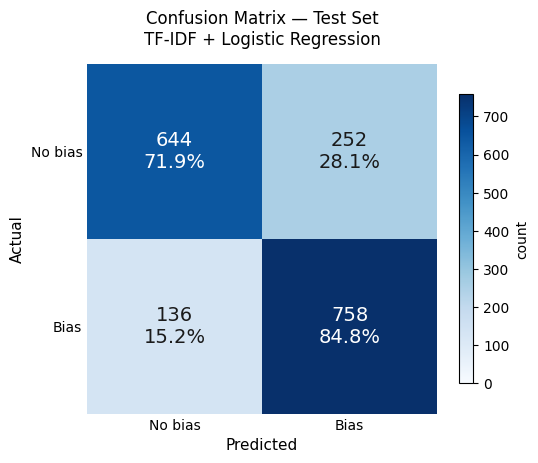

In [23]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, pred_test)
labels = ["No bias", "Bias"]

fig, ax = plt.subplots(figsize=(5.5, 4.8))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.max())

# annotate each cell with count and row-percentage
for i in range(2):
    for j in range(2):
        pct = cm[i, j] / cm[i].sum() * 100
        ax.text(j, i, f"{cm[i, j]}\n{pct:.1f}%",
                ha="center", va="center", fontsize=14,
                color="white" if cm[i, j] > cm.max() * 0.5 else "#1a1a1a")

ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set_xlabel("Predicted", fontsize=11)
ax.set_ylabel("Actual", fontsize=11)
ax.set_title("Confusion Matrix — Test Set\nTF-IDF + Logistic Regression",
             fontsize=12, pad=14)

# clean frame
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(length=0)
fig.colorbar(im, ax=ax, shrink=0.75, label="count")

plt.tight_layout()
plt.savefig("confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.show()